# 01 · Data quality and provenance

Historical demonstration. Audit real, consented item histories without modifying the original. Primary analysis retains gift cards. [Dataset](https://doi.org/10.7910/DVN/YGLYDY), [paper](https://www.nature.com/articles/s41597-024-03329-6).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RUN = Path(__import__("os").environ.get("AMAZON_CLV_RUN", str(ROOT / "runs" / "main")))
assert (RUN / "manifest.json").exists(), "Run python -m amazon_clv run first"
audit = json.loads((RUN / "data_audit.json").read_text())
manifest = json.loads((RUN / "manifest.json").read_text())
pd.set_option("display.max_columns", 20)
print("Source MD5:", audit["md5"], "| Model version:", manifest["run_version"])


Source MD5: 3549d72735b1211ab009ff0177b94bd9 | Model version: amazon-clv-1.0-6efb098a6e


## Check identity and reconcile exclusions
MD5 verifies the mirror's bytes against the original deposit. SHA256 tracks this exact analytical input. Neither certifies each source record's correctness.

In [2]:
assert audit["checksum_verified"]
assert audit["valid_rows"] + sum(audit["exclusions_sequential"].values()) == audit["source_rows"]
display(pd.Series({k:audit[k] for k in ["source_rows","source_customers","valid_rows","valid_customers","source_date_min","source_date_max","identical_rows_retained","gift_rows"]},name="Audit"))
display(pd.Series(audit["exclusions_sequential"],name="Sequential excluded rows"))
display(pd.Series(audit["later_records_by_year"],name="Later dates excluded"))

source_rows                   1850717
source_customers                 5027
valid_rows                    1737058
valid_customers                  5015
source_date_min            2018-01-01
source_date_max            2024-08-15
identical_rows_retained         10911
gift_rows                       39006
Name: Audit, dtype: object

missing_customer_id         0
invalid_date                0
invalid_price               0
invalid_quantity            0
before_2018                 0
after_2022_10_31       113659
Name: Sequential excluded rows, dtype: int64

2022    73735
2023    39923
2024        1
Name: Later dates excluded, dtype: int64

## Missing descriptions, exact purchase values, and coverage
UNKNOWN is explicit. Identical rows remain because no order identifier resolves whether they are duplicates. Coverage ends exclusively on 2022-11-01, independently of each customer's last observed purchase.

In [3]:
tx = pd.read_parquet(RUN / "transactions.parquet")
assert tx.date.ge("2018-01-01").all() and tx.date.lt("2022-11-01").all()
assert (tx.value_cents == tx.unit_price_cents * tx.quantity).all()
assert tx.value_cents.sum() == audit["total_value_cents"]
display(pd.Series({k:v for k,v in audit.items() if k.startswith("missing_")},name="Explicit missing descriptions"))
print(f"Recorded purchase value: ${tx.value_cents.sum()/100:,.2f}")
display(tx.groupby(tx.date.dt.year).agg(item_rows=("value_cents","size"),accounts=("customer_id","nunique"),value_cents=("value_cents","sum")))

missing_category      88717
missing_product_id      943
missing_title         88974
missing_state         82469
Name: Explicit missing descriptions, dtype: int64

Recorded purchase value: $41,258,953.83


,item_rows,accounts,value_cents
date,,,
2018,225465,4281,550538455
2019,266016,4520,643533667
2020,409212,4723,933803352
2021,467870,4862,1112006965
2022,368495,4821,886012944


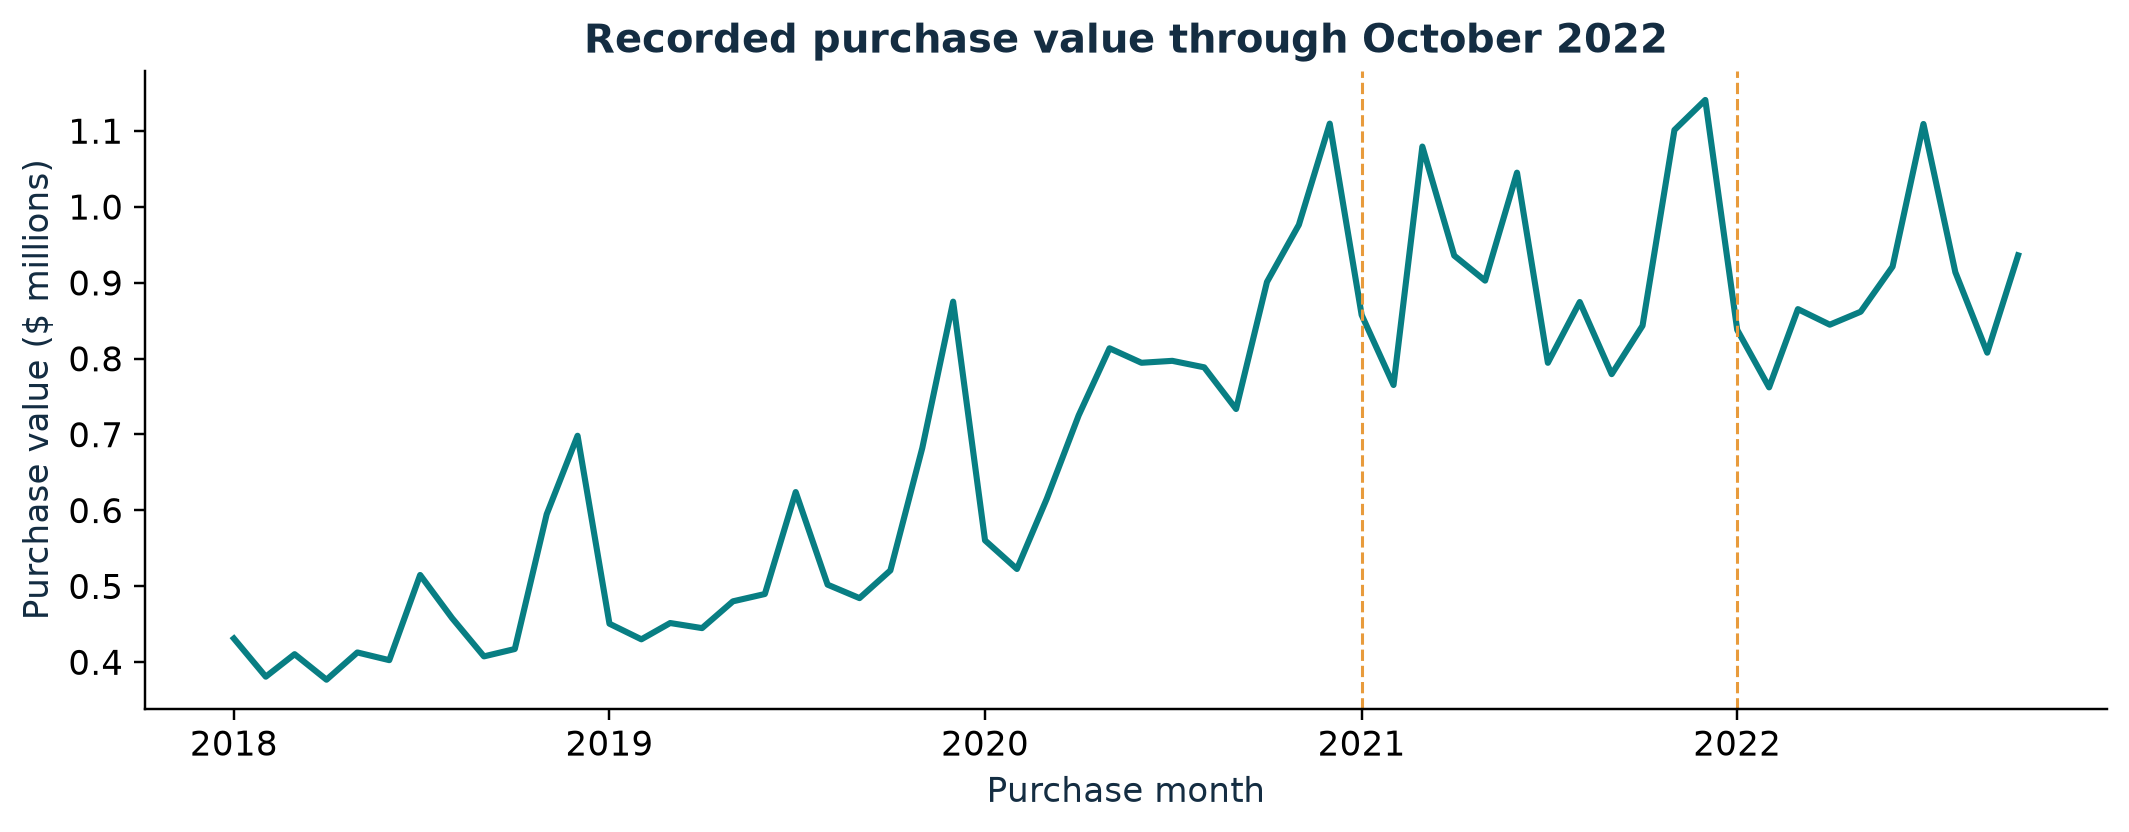

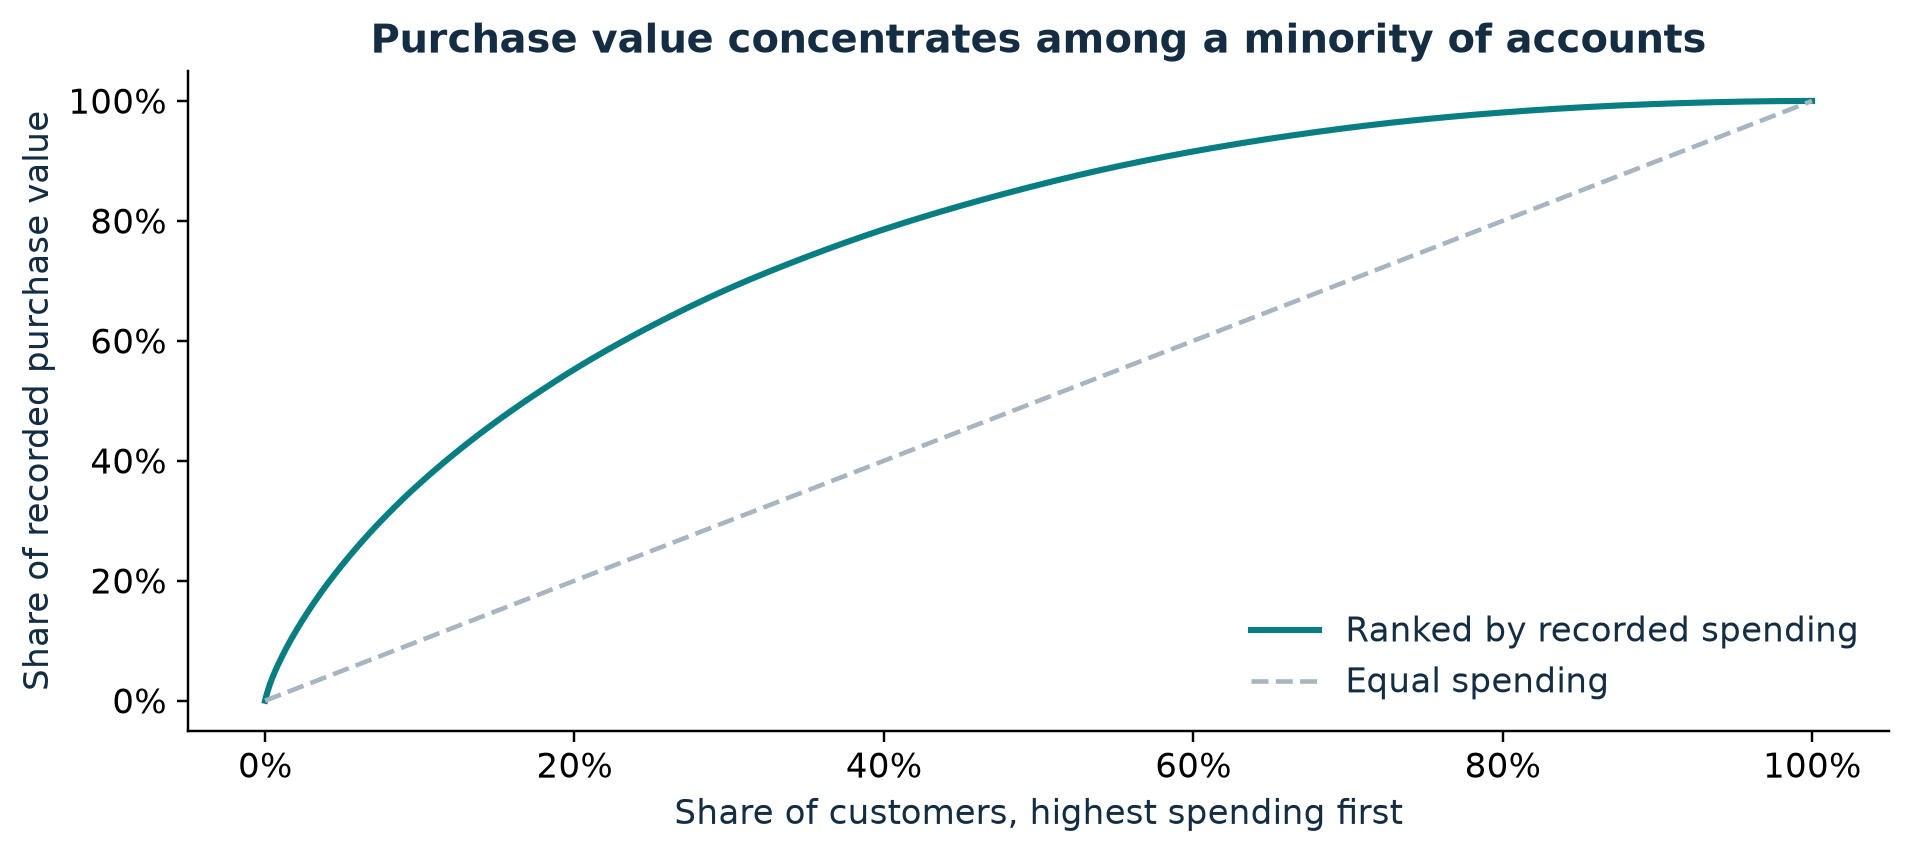

In [4]:
display(Image(filename=str(RUN / "charts" / "monthly_spending.png")))
display(Image(filename=str(RUN / "charts" / "concentration.png")))

## Interpretation
This is a consent-selected retrospective account cohort, with roughly 5,000 accounts rather than 1.85 million independent customers. Shared accounts, selection at recruitment, left-truncated history, and source anomalies limit inference. Customer purchase value differs from Amazon net revenue/profit. Do not use 2023/2024 records to claim a more recent validated cohort.